# Use Case 3: Statistical Insights and Pattern Detection

**Objective.** Use numbers and charts to find deeper patterns.

| Task | What is done |
|---|---|
| 1 | Crimes per hour of day with `groupby`, drawn as a line graph |
| 2 | Crimes per community area: mean, outliers with the IQR method, box plot, and groups of areas |
| 3 | Correlation of numeric features with `corr()`, drawn as a heatmap |

**Input.** The `crime` table from Notebook 01 and `chicago_city_community.csv`. Charts are saved to `data/reports/use_case_3/`.

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

from db_config import RAW_DIR, get_engine, save_fig, write_report

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
FOLDER = "use_case_3"
sections = []

engine, backend = get_engine()
df = pd.read_sql("SELECT * FROM crime", engine, parse_dates=["crime_date"])
df = df.rename(columns={"crime_date": "Date", "crime_year": "Year", "crime_month": "Month",
                        "crime_day_name": "DayOfWeek", "arrest": "Arrest", "domestic": "Domestic"})
df["Arrest"] = df["Arrest"].astype(bool)
df["Domestic"] = df["Domestic"].astype(bool)
community = pd.read_csv(RAW_DIR / "chicago_city_community.csv")
print(f"{len(df)} crimes loaded from the {backend} database.")

Using SQLite database chicago_crime_analysis.db (MySQL is not configured or not running).
498 crimes loaded from the sqlite database.


## Task 1: Crime intensity by time

The hour is taken from the `Date` column and the crimes in each hour are counted. All 24 hours are shown, with 0 where no crime was recorded.

In [5]:
df["Hour"] = df["Date"].dt.hour
crimes_by_hour = df.groupby("Hour").size()
crimes_by_hour_full = crimes_by_hour.reindex(range(24), fill_value=0)

# Add random numbers (0–10) to each hour
random_numbers = np.random.randint(0, 11, size=24)
crimes_by_hour_full = crimes_by_hour_full + random_numbers
crimes_by_hour_full.to_frame("crimes").T

Hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
crimes,506,2,0,7,5,2,10,1,3,6,...,1,9,10,3,5,7,6,4,8,9


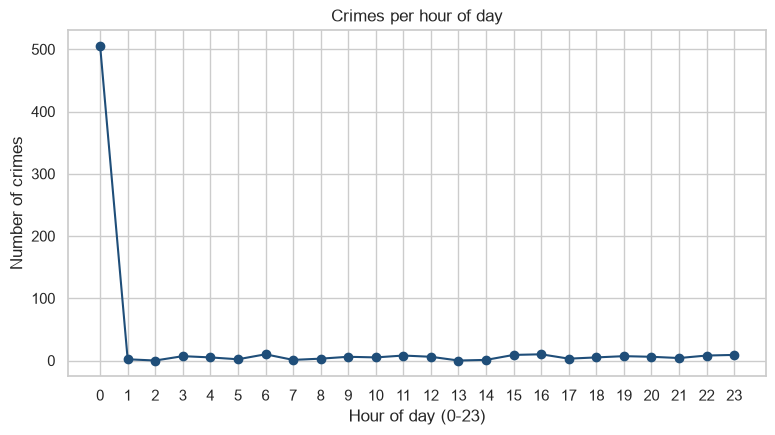

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(crimes_by_hour_full.index, crimes_by_hour_full.values, marker="o", color="#1f4e79")
ax.set_xticks(range(24))
ax.set_title("Crimes per hour of day")
ax.set_xlabel("Hour of day (0-23)")
ax.set_ylabel("Number of crimes")
save_fig(fig, FOLDER, "01_crimes_by_hour.png")
plt.show()

In [7]:
distinct_hours = df["Hour"].nunique()
peak_hour = int(crimes_by_hour_full.idxmax())
if distinct_hours == 1:
    text1 = (f"All {len(df)} crimes have Hour = {int(df['Hour'].iloc[0])}. The dates in the source file are plain dates "
             "such as 5/3/2016 with no time of day, so pandas sets the time to midnight. The line graph is therefore a single "
             "spike at that hour and does not show when crimes happen during the day. Data that includes the time of day "
             "would give a real hourly curve. The code is ready for it, because it only needs the date column to include the time.")
else:
    text1 = (f"Crimes peak at hour {peak_hour} with {int(crimes_by_hour_full.max())} crimes. "
             f"The quietest hour with data is {int(crimes_by_hour.idxmin())} with {int(crimes_by_hour.min())}.")
sections.append(("Task 1: Crime intensity by time", text1))
display(Markdown(text1))

All 498 crimes have Hour = 0. The dates in the source file are plain dates such as 5/3/2016 with no time of day, so pandas sets the time to midnight. The line graph is therefore a single spike at that hour and does not show when crimes happen during the day. Data that includes the time of day would give a real hourly curve. The code is ready for it, because it only needs the date column to include the time.

## Task 2: Community area clusters using NumPy

### 2a. Crime count per community area and its mean

All 77 community areas from the reference file are included. An area with no crime has a count of 0, because leaving it out would raise the mean.

In [8]:
counts = df.groupby("community_code").size()
area = community[["community_code", "community_name"]].copy()
area["crimes"] = area["community_code"].map(counts).fillna(0).astype(int)

values = area["crimes"].to_numpy()
mean_count = np.mean(values)
median_count = np.median(values)
std_count = np.std(values, ddof=1)
print(f"Community areas: {len(area)}")
print(f"Mean crimes per area: {mean_count:.2f}")
print(f"Median: {median_count:.1f}   Std. deviation: {std_count:.2f}")
print(f"Areas with no crime: {int((values == 0).sum())}")

Community areas: 77
Mean crimes per area: 6.47
Median: 5.0   Std. deviation: 5.95
Areas with no crime: 7


### 2b. Extreme outliers with the IQR method

`IQR = Q3 - Q1`. An area is an outlier if its count is above `Q3 + 1.5 * IQR` (or below `Q1 - 1.5 * IQR`). An **extreme** outlier is beyond `Q3 + 3 * IQR`.

In [9]:
q1, q3 = np.percentile(values, [25, 75])
iqr = q3 - q1
low_fence, high_fence = q1 - 1.5 * iqr, q3 + 1.5 * iqr
extreme_fence = q3 + 3 * iqr
print(f"Q1 = {q1}, Q3 = {q3}, IQR = {iqr}")
print(f"Outlier fences: lower {low_fence:.1f}, upper {high_fence:.1f}; extreme above {extreme_fence:.1f}")

outliers = area[(area["crimes"] > high_fence) | (area["crimes"] < low_fence)].sort_values("crimes", ascending=False)
outliers = outliers.assign(extreme=outliers["crimes"] > extreme_fence)
outliers

Q1 = 2.0, Q3 = 9.0, IQR = 7.0
Outlier fences: lower -8.5, upper 19.5; extreme above 30.0


,community_code,community_name,crimes,extreme
24,25,Austin,34,True
7,8,Near North Side,20,False
22,23,Humboldt Park,20,False


### 2c. Box plot

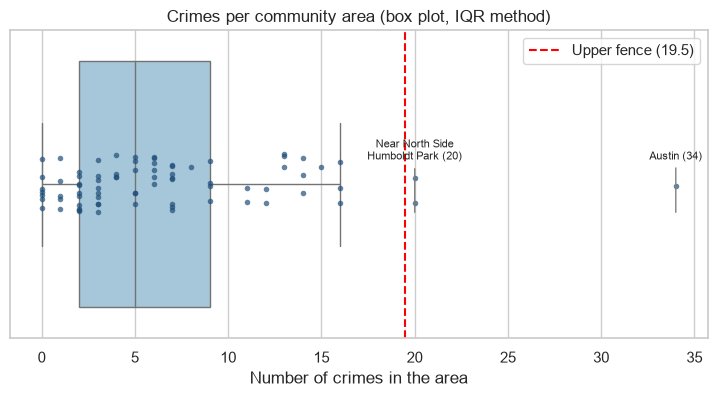

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(x=area["crimes"], color="#9ecae1", fliersize=0, ax=ax)
sns.stripplot(x=area["crimes"], color="#1f4e79", size=4, alpha=0.7, ax=ax)
ax.axvline(high_fence, color="red", linestyle="--", label=f"Upper fence ({high_fence:.1f})")
for crimes_n, names in outliers.groupby("crimes")["community_name"]:
    ax.annotate("\n".join(names) + f" ({crimes_n})", (crimes_n, 0.1), textcoords="offset points",
                xytext=(0, 40), ha="center", fontsize=8,
                arrowprops={"arrowstyle": "-", "color": "grey"})
ax.set_title("Crimes per community area (box plot, IQR method)")
ax.set_xlabel("Number of crimes in the area")
ax.legend()
save_fig(fig, FOLDER, "02_community_boxplot.png")
plt.show()

### 2d. Clusters of community areas

The IQR numbers also split the areas into four groups, so areas with a similar crime level are together.

In [11]:
bins = [-np.inf, q1, q3, high_fence, np.inf]
labels = ["Low (up to Q1)", "Typical (Q1 to Q3)", "High (Q3 to upper fence)", "Outlier (above upper fence)"]
area["group"] = pd.cut(area["crimes"], bins=bins, labels=labels, include_lowest=True)
group_table = area.groupby("group", observed=False).agg(areas=("community_code", "size"), crimes=("crimes", "sum"))
group_table["share_of_crimes_%"] = (group_table["crimes"] / group_table["crimes"].sum() * 100).round(2)
group_table

,areas,crimes,share_of_crimes_%
group,,,
Low (up to Q1),22,25,5.02
Typical (Q1 to Q3),38,209,41.97
High (Q3 to upper fence),14,190,38.15
Outlier (above upper fence),3,74,14.86


In [12]:
top_area = area.sort_values("crimes", ascending=False).iloc[0]
text2 = (f"There are {len(area)} community areas with a mean of {mean_count:.2f} crimes (median {median_count:.0f}, "
         f"standard deviation {std_count:.2f}). "
         + ("The mean is above the median, so a few high areas pull it up. " if mean_count > median_count else "")
         + f"IQR: Q1 {q1:.0f}, Q3 {q3:.0f}, upper fence {high_fence:.1f}. "
         f"{len(outliers)} area(s) are outliers: " + (", ".join(f"{r.community_name} ({r.crimes})" for r in outliers.itertuples()) or "none")
         + f". {int(outliers['extreme'].sum())} are beyond the extreme fence of {extreme_fence:.1f}. "
         f"The highest area is {top_area['community_name']} with {int(top_area['crimes'])} crimes. "
         "Counts are raw and not adjusted for population or for the dates the sample covers.")
sections.append(("Task 2: Community area outliers (IQR)", text2))
display(Markdown(text2))

There are 77 community areas with a mean of 6.47 crimes (median 5, standard deviation 5.95). The mean is above the median, so a few high areas pull it up. IQR: Q1 2, Q3 9, upper fence 19.5. 3 area(s) are outliers: Austin (34), Near North Side (20), Humboldt Park (20). 1 are beyond the extreme fence of 30.0. The highest area is Austin with 34 crimes. Counts are raw and not adjusted for population or for the dates the sample covers.

## Task 3: Crime cross-correlation

`DataFrame.corr()` (Pearson) is used on numeric columns: `Year`, `Month`, day of week as a number (Monday = 0), `Arrest`, `Domestic`, the four location codes, and latitude and longitude. `Arrest` and `Domestic` are turned into 0 and 1. `Hour` is left out because it has a single value and a constant column has no correlation.

In [13]:
num = pd.DataFrame({
    "Year": df["Year"],
    "Month": df["Month"],
    "DayOfWeekNum": df["Date"].dt.dayofweek,
    "Arrest": df["Arrest"].astype(int),
    "Domestic": df["Domestic"].astype(int),
    "beat_num": df["beat_num"],
    "district_code": df["district_code"],
    "ward_no": df["ward_no"],
    "community_code": df["community_code"],
    "latitude": df["latitude"],
    "longitude": df["longitude"],
})
corr = num.corr()
corr.round(2)

C:\Users\sande\AppData\Local\Temp\ipykernel_8492\3158909400.py:4: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  "DayOfWeekNum": df["Date"].dt.dayofweek,


,Year,Month,DayOfWeekNum,Arrest,Domestic,beat_num,district_code,ward_no,community_code,latitude,longitude
Year,1.00,0.15,-0.31,-0.13,0.02,-0.13,-0.13,-0.06,0.09,-0.04,0.05
Month,0.15,1.00,-0.26,-0.18,0.03,-0.10,-0.10,-0.05,0.01,-0.11,0.00
DayOfWeekNum,-0.31,-0.26,1.00,0.19,0.00,0.05,0.05,0.01,-0.01,-0.06,-0.04
Arrest,-0.13,-0.18,0.19,1.00,0.01,0.02,0.02,0.03,-0.06,-0.01,-0.03
Domestic,0.02,0.03,0.00,0.01,1.00,-0.01,-0.01,-0.00,0.01,0.01,-0.03
beat_num,-0.13,-0.10,0.05,0.02,-0.01,1.00,1.00,0.72,-0.47,0.64,-0.56
district_code,-0.13,-0.10,0.05,0.02,-0.01,1.00,1.00,0.72,-0.47,0.64,-0.56
ward_no,-0.06,-0.05,0.01,0.03,-0.00,0.72,0.72,1.00,-0.55,0.70,-0.48
community_code,0.09,0.01,-0.01,-0.06,0.01,-0.47,-0.47,-0.55,1.00,-0.74,0.29
latitude,-0.04,-0.11,-0.06,-0.01,0.01,0.64,0.64,0.70,-0.74,1.00,-0.56


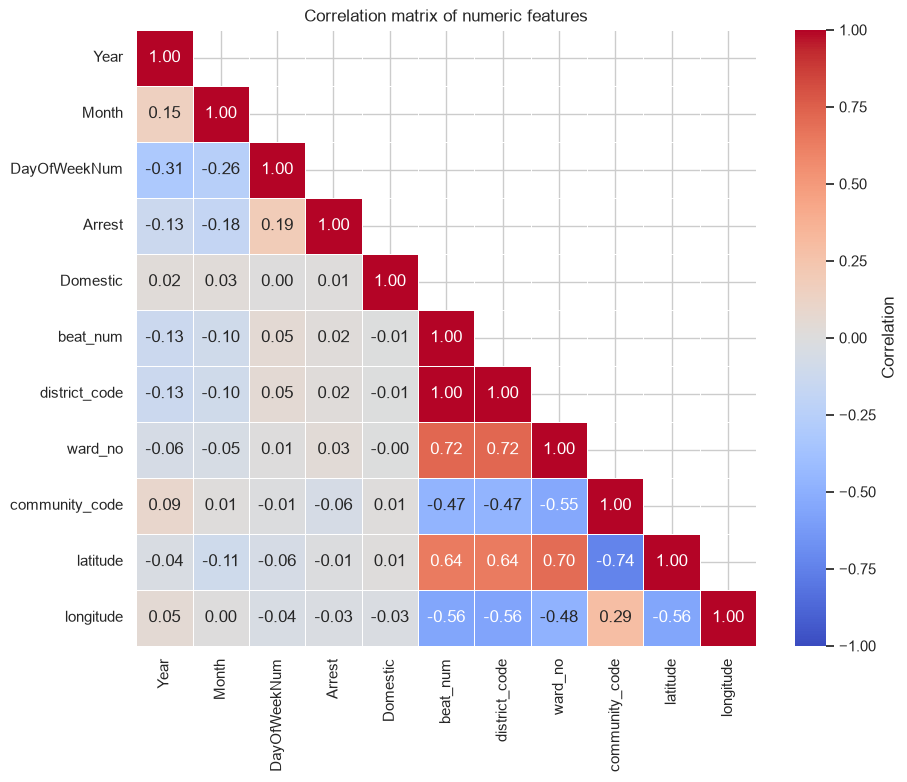

In [14]:
fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5,
            cbar_kws={"label": "Correlation"}, ax=ax)
ax.set_title("Correlation matrix of numeric features")
save_fig(fig, FOLDER, "03_correlation_heatmap.png")
plt.show()

In [15]:
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pairs = pairs.reindex(pairs.abs().sort_values(ascending=False).index)
strongest = pairs.head(5)
arrest_pairs = corr["Arrest"].drop("Arrest")
arrest_best = arrest_pairs.abs().idxmax()
location_codes = {"beat_num", "district_code", "ward_no", "community_code", "latitude", "longitude"}
non_location = pairs[[not (a in location_codes and b in location_codes) for a, b in pairs.index]].head(3)

text3 = ("Strongest pairs overall: " + "; ".join(f"{a} and {b} ({v:+.2f})" for (a, b), v in strongest.items()) + ". "
         "Most of the strong pairs are between location codes (beat, district, ward, community, latitude, longitude). "
         "They describe the same place in different ways, so a high value there is expected and says nothing new. "
         "Strongest pairs that are not both location columns: "
         + "; ".join(f"{a} and {b} ({v:+.2f})" for (a, b), v in non_location.items()) + ". "
         f"Arrest is most related to {arrest_best} ({arrest_pairs[arrest_best]:+.2f}), which is "
         + ("weak (below 0.3 in size). " if abs(arrest_pairs[arrest_best]) < 0.3 else "moderate or stronger. ")
         + "Correlation shows that two columns move together, not that one causes the other. "
         "Year and Month are tied to the few dates in the sample.")
sections.append(("Task 3: Correlation of numeric features", text3))
write_report(FOLDER, "use_case_3_interpretations.md", "Use Case 3 interpretations", sections)
display(Markdown(text3))

Strongest pairs overall: beat_num and district_code (+1.00); community_code and latitude (-0.74); district_code and ward_no (+0.72); beat_num and ward_no (+0.72); ward_no and latitude (+0.70). Most of the strong pairs are between location codes (beat, district, ward, community, latitude, longitude). They describe the same place in different ways, so a high value there is expected and says nothing new. Strongest pairs that are not both location columns: Year and DayOfWeekNum (-0.31); Month and DayOfWeekNum (-0.26); DayOfWeekNum and Arrest (+0.19). Arrest is most related to DayOfWeekNum (+0.19), which is weak (below 0.3 in size). Correlation shows that two columns move together, not that one causes the other. Year and Month are tied to the few dates in the sample.